# 🎯 03 · Backpropagation for the Output Layer

> **Module 02 – Feed-Forward Networks and Backpropagation** · Notebook 3 of 6
> Course notes: page 4 ($w_{ji}\leftarrow w_{ji}+\Delta w_{ji}$, $\ \frac{\partial E}{\partial w_{ji}}=\frac{\partial E}{\partial o_j}\frac{\partial o_j}{\partial net_j}\frac{\partial net_j}{\partial w_{ji}}$, $\ \delta_j\leftarrow-\frac{\partial E}{\partial net_j}$, $\ \Delta w_{ji}=\eta\ \delta_j\ x_{ji}$) and page 8 ($\frac{\partial E}{\partial W^o}=\delta^o(o^{h2})^\top$) · Mitchell §4.5.3

Training means: for **every weight**, find out whether nudging it up makes the error go up or down, and by how much. That number is $\partial E/\partial w$. The output layer is the easy place to start, because its weights **directly influence the output** (as the notes say). Hidden layers come in notebook 04.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | The chain rule, and why gradients are products of "local slopes" |
| 2 | The **error term** $\delta_k$ of an output neuron and the update $\Delta w_{kj}=\eta\ \delta_k\ x_{kj}$ |
| 3 | A full numeric example, checked against a brute-force gradient |
| 4 | The matrix form $\frac{\partial E}{\partial W^{o}}=-\delta^o(o^{h2})^\top$ for a whole batch |
| 5 | **Gradient checking** – the most important debugging tool in deep learning |
| 6 | Softmax + cross-entropy, where $\delta$ becomes simply $t-p$ |
| 7 | Why cross-entropy trains faster than squared error |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(1)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def softmax(Z):
    Z = Z - Z.max(axis=0, keepdims=True)          # column-wise, numerically stable
    E = np.exp(Z)
    return E / E.sum(axis=0, keepdims=True)

---
## 1 · The variables

### 📖 Notation for the whole of module 02 (same as the course notes)

| Symbol | Shape | Meaning |
|---|---|---|
| $L$ | number | number of layers with weights (hidden + output). The input is "layer 0". |
| $n_l$ | number | number of neurons in layer $l$ ($n_0$ = number of inputs) |
| $\vec x = o^{[0]}$ | $n_0\times1$ | one input example, a **column** vector |
| $w_{ji}$ | number | weight on the wire **from** neuron $i$ (layer $l-1$) **to** neuron $j$ (layer $l$). First index = destination. |
| $W^{[l]}$ | $n_l\times n_{l-1}$ | all weights of layer $l$; **row $j$** = the incoming weights of neuron $j$ (notes: $W^{h1}_{5\times4}$) |
| $b^{[l]}$ | $n_l\times1$ | biases of layer $l$, one per neuron (the weight of the constant input $x_0=1$) |
| $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$ | $n_l\times1$ | net inputs of layer $l$; entry $j$ is $net_j=\sum_i w_{ji}\ o_i+b_j$ |
| $o^{[l]}=g(net^{[l]})$ | $n_l\times1$ | outputs (activations) of layer $l$; $g$ = activation function, e.g. sigmoid |
| $x_{ji}$ | number | the input that arrives at neuron $j$ from $i$, i.e. $x_{ji}=o_i$ (Mitchell / notes) |
| $t_k$ | number | target for output neuron $k$ |
| $E$ | number | the error (loss) we minimise |
| $\delta_j=-\dfrac{\partial E}{\partial net_j}$ | number | **error term** of neuron $j$ ("how much the error drops if $net_j$ rises") |
| $\eta$ | number | learning rate |
| $N$ | number | batch size; a batch is $X\in\mathbb R^{n_0\times N}$ with **one example per column** |

The notes also name layers by role: $h1$, $h2$ (hidden) and $o$ (output), e.g. $o^{h1}=\sigma(W^{h1}x+b^{h1})$.
In this notebook we look at **one output neuron $k$** fed by **hidden neurons $j$** of the last hidden layer:

| Symbol | Meaning |
|---|---|
| $o_j$ | output of hidden neuron $j$ (= the input $x_{kj}$ arriving at output neuron $k$) |
| $w_{kj}$ | weight from hidden neuron $j$ to output neuron $k$ |
| $net_k=\sum_j w_{kj}\ o_j+b_k$ | net input of output neuron $k$ |
| $o_k=\sigma(net_k)$ | its output |
| $t_k$ | its target |
| $E=\tfrac12\sum_k(t_k-o_k)^2$ | squared error for one example (notes: summed over $d\in D$ as well) |

---
## 2 · The chain rule: rates multiply ⛓️

If $E$ depends on $o$, $o$ depends on $net$, and $net$ depends on $w$, then a small change in $w$ ripples through the chain:

$$\frac{\partial E}{\partial w}=\frac{\partial E}{\partial o}\cdot\frac{\partial o}{\partial net}\cdot\frac{\partial net}{\partial w}$$

*Everyday version:* petrol costs ₹8 per km and you drive 60 km per hour, so driving costs $8\times60=$ ₹480 per hour. **Rates multiply along a chain.**

Here is the whole network as a chain. The forward pass (blue) computes and **stores** every box; the backward pass (red) multiplies local slopes from right to left.

In [2]:
# ---------- plotting helper (visualisation only) ----------
def draw_chain(ax):
    boxes = ["$x=o^{[0]}$", "$net^{h}$", "$o^{h}$", "$net^{o}$", "$o^{o}$", "$E$"]
    fwd = ["$W^{h}\\cdot+b^{h}$", "$\\sigma$", "$W^{o}\\cdot+b^{o}$", "$\\sigma$", "$\\frac{1}{2}\\sum(t-o)^2$"]
    bwd = ["", "$\\odot\\,o^h(1-o^h)$", "$(W^{o})^{\\top}\\cdot$", "$\\odot\\,o^o(1-o^o)$", "$-(t-o^o)$"]
    xs = np.arange(len(boxes)) * 2.2
    for i, (xp, lab) in enumerate(zip(xs, boxes)):
        ec = C["red"] if i == len(boxes) - 1 else (C["muted"] if i == 0 else C["blue"])
        ax.add_patch(plt.Rectangle((xp - 0.6, -0.35), 1.2, 0.7, fill=True, fc="white", ec=ec, lw=2, zorder=2))
        ax.text(xp, 0, lab, ha="center", va="center", fontsize=13, zorder=3)
    for i in range(len(boxes) - 1):
        ax.annotate("", xy=(xs[i + 1] - 0.62, 0.12), xytext=(xs[i] + 0.62, 0.12),
                    arrowprops=dict(arrowstyle="-|>", color=C["blue"], lw=2))
        ax.text((xs[i] + xs[i + 1]) / 2, 0.42, fwd[i], ha="center", color=C["blue"], fontsize=11)
        if i >= 1:
            ax.annotate("", xy=(xs[i] + 0.1, -0.38), xytext=(xs[i + 1] - 0.1, -0.38),
                        arrowprops=dict(arrowstyle="-|>", color=C["red"], lw=2, connectionstyle="arc3,rad=-0.45"))
            ax.text((xs[i] + xs[i + 1]) / 2, -1.12, bwd[i], ha="center", color=C["red"], fontsize=11)
    ax.text(xs[3], -0.62, "$\\delta^{o}$", color=C["red"], fontsize=12, ha="center")
    ax.text(xs[1], -0.62, "$\\delta^{h}$", color=C["red"], fontsize=12, ha="center")
    ax.text(xs[2] + 1.1, 1.0, "forward: compute and store", color=C["blue"], ha="center", fontweight="bold")
    ax.text(xs[2] + 1.1, -1.55, "backward: multiply local slopes, right to left", color=C["red"], ha="center", fontweight="bold")
    ax.set_xlim(-0.8, xs[-1] + 0.8); ax.set_ylim(-1.8, 1.25); ax.axis("off")

📊 **Plot:** the chain diagram.

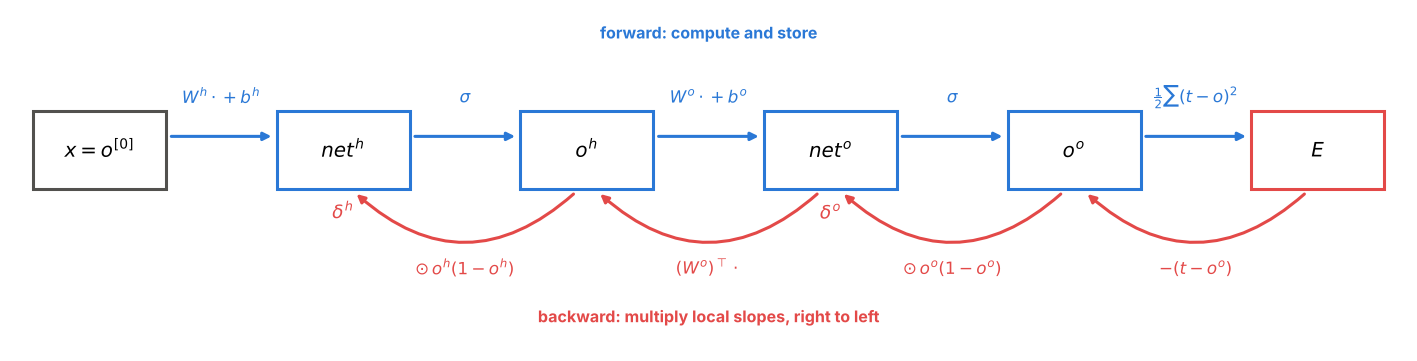

In [3]:
fig, ax = plt.subplots(figsize=(13, 3.4))
draw_chain(ax)
plt.tight_layout(); plt.show()

---
## 3 · Deriving the update for an output weight $w_{kj}$ ✍️

Follow the notes (page 4), one factor at a time:

$$\frac{\partial E}{\partial w_{kj}} =\underbrace{\frac{\partial E}{\partial o_k}}_{\text{①}}\cdot \underbrace{\frac{\partial o_k}{\partial net_k}}_{\text{②}}\cdot \underbrace{\frac{\partial net_k}{\partial w_{kj}}}_{\text{③}}$$

| factor | how we get it | value | meaning |
|---|---|---|---|
| ① $\dfrac{\partial E}{\partial o_k}$ | $E=\tfrac12\sum_k(t_k-o_k)^2$; only term $k$ depends on $o_k$ | $-(t_k-o_k)$ | how wrong the output is |
| ② $\dfrac{\partial o_k}{\partial net_k}$ | sigmoid derivative (module 01) | $o_k(1-o_k)$ | how sensitive the neuron is. *"Activation function changes, only this partial derivative changes."* |
| ③ $\dfrac{\partial net_k}{\partial w_{kj}}$ | $net_k=\sum_j w_{kj}o_j+b_k$ | $o_j=x_{kj}$ | what came in on that wire |

Name the first two factors together. The notes define the **error term** $\delta_k=-\dfrac{\partial E}{\partial net_k}$:

$$\boxed{\delta_k=(t_k-o_k)\ o_k(1-o_k)}\qquad\Longrightarrow\qquad \frac{\partial E}{\partial w_{kj}}=-\delta_k\ x_{kj}\qquad\Longrightarrow\qquad \boxed{\Delta w_{kj}=-\eta\frac{\partial E}{\partial w_{kj}}=\eta\ \delta_k\ x_{kj}}$$

For the bias the "input" is the constant 1, so $\Delta b_k=\eta\ \delta_k$.

> 💡 **Read it as:** *weight change = learning rate × (blame at the neuron) × (signal on the wire).* Every quantity is **local**: the neuron's own output and target, and the signal on its own input wire. The notes: *"For back prop you need only local information."*

### What does $\delta_k$ look like?
For a target $t_k=1$, here are the two factors and their product as the output $o_k$ varies:

**Compute** the two factors and their product for 500 output values between 0 and 1 (target fixed at 1):

In [4]:
o = np.linspace(0.001, 0.999, 500)
t = 1.0
factor_error = t - o                      # ①  how wrong
factor_slope = o * (1 - o)                # ②  how sensitive
delta_curve = factor_error * factor_slope # δ = ① × ②
print(f"largest δ = {delta_curve.max():.3f} at o = {o[delta_curve.argmax()]:.2f};   δ at o = 0.01: {delta_curve[np.searchsorted(o, 0.01)]:.4f}")

largest δ = 0.148 at o = 0.33;   δ at o = 0.01: 0.0108


📊 **Plot:** the three curves. The shaded strip on the left is the "confidently wrong" region.

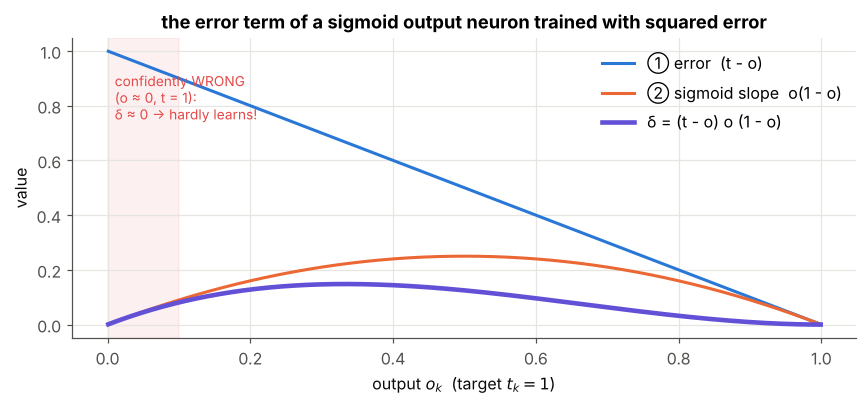

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(o, factor_error, color=C["blue"], label="① error  (t - o)")
ax.plot(o, factor_slope, color=C["orange"], label="② sigmoid slope  o(1 - o)")
ax.plot(o, delta_curve, color=C["violet"], lw=3, label="δ = (t - o) o (1 - o)")
ax.axvspan(0, 0.1, color=C["red"], alpha=0.08)
ax.text(0.01, 0.75, "confidently WRONG\n(o ≈ 0, t = 1):\nδ ≈ 0 → hardly learns!", color=C["red"], fontsize=9)
ax.set_xlabel("output $o_k$  (target $t_k = 1$)"); ax.set_ylabel("value")
ax.set_title("the error term of a sigmoid output neuron trained with squared error")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Notice the problem on the left: when the neuron is **confidently wrong** ($o_k\approx0$ but $t_k=1$), the slope $o_k(1-o_k)\approx0$ kills the error term. We will fix this with cross-entropy in section 7.

---
## 4 · A complete numeric example (the 2-2-1 network from notebook 02) 🔢

Same weights as before; target $t=1$, learning rate $\eta=0.5$. Only the **output layer** is updated here.

**Step A – parameters, target and learning rate.**

In [6]:
x  = np.array([[1.0], [0.5]])
W1 = np.array([[0.2, 0.4], [-0.3, 0.1]]); b1 = np.array([[0.1], [-0.1]])
W2 = np.array([[0.6, -0.2]]);              b2 = np.array([[0.05]])
t, eta = 1.0, 0.5

**Step B – forward pass, keeping every intermediate result.** The hidden outputs `o1` are exactly the inputs $x_{kj}$ that the output neuron receives, so we need them for factor ③.

In [7]:
o1 = sigmoid(W1 @ x + b1)                  # hidden outputs  = inputs x_kj of the output neuron
o2 = sigmoid(W2 @ o1 + b2)                 # network output o_k
E = 0.5 * (t - o2[0, 0]) ** 2
print(f"hidden outputs o_j = {o1.ravel().round(4)}   output o_k = {o2[0, 0]:.4f}   E = {E:.4f}")

hidden outputs o_j = [0.6225 0.4134]   output o_k = 0.5844   E = 0.0864


**Step C – the error term, factor by factor.** `f1` is ① and `f2` is ②; their product is $\partial E/\partial net_k$, and the notes' $\delta_k$ is its negative.

In [8]:
f1 = -(t - o2[0, 0])                        # ① dE/do_k
f2 = o2[0, 0] * (1 - o2[0, 0])              # ② do_k/dnet_k
delta_k = -(f1 * f2)                        # δ_k = -dE/dnet_k = (t - o) o (1 - o)
print(f"① dE/do = {f1:.4f}   ② do/dnet = {f2:.4f}   δ_k = {delta_k:.4f}")

① dE/do = -0.4156   ② do/dnet = 0.2429   δ_k = 0.1009


**Step D – the update** $\Delta w_{kj}=\eta\ \delta_k\ x_{kj}$. `o1.T` is a row $(1\times2)$, so `delta_k * o1.T` has the same shape as `W2`. The bias input is 1, so $\Delta b_k=\eta\ \delta_k$.

In [9]:
dW2 = eta * delta_k * o1.T                  # Δw_kj = η δ_k x_kj   (x_kj = o_j)
db2 = eta * delta_k                         # Δb_k  = η δ_k
print(f"ΔW2 = {dW2.ravel().round(5)}   Δb2 = {db2:.5f}")

ΔW2 = [0.0314 0.0209]   Δb2 = 0.05047


**Step E – did it help?** Apply the update and run the output layer again: the output should move towards 1 and the error should drop.

In [10]:
W2_new, b2_new = W2 + dW2, b2 + db2
o2_new = sigmoid(W2_new @ o1 + b2_new)
print(f"after the update: output {o2[0, 0]:.4f} → {o2_new[0, 0]:.4f},  "
      f"E {E:.5f} → {0.5 * (t - o2_new[0, 0]) ** 2:.5f}  ✅ error went down")

after the update: output 0.5844 → 0.6034,  E 0.08637 → 0.07866  ✅ error went down


**Check by hand:** $\delta_k=(1-0.5844)\times0.5844\times0.4156=0.1009$.
$\Delta w_{k1}=0.5\times0.1009\times0.6225=0.0314$ and $\Delta w_{k2}=0.5\times0.1009\times0.4134=0.0209$.
Both weights grow because the output was too low and both hidden inputs were positive.

---
## 5 · Gradient checking: trust, but verify 🔬

How do we know the formula is right? Compute the slope **the slow, brute-force way** and compare:

$$\frac{\partial E}{\partial\theta}\approx\frac{E(\theta+\varepsilon)-E(\theta-\varepsilon)}{2\varepsilon},\qquad \text{relative error}=\frac{\lVert g_{\text{analytic}}-g_{\text{numeric}}\rVert}{\lVert g_{\text{analytic}}\rVert+\lVert g_{\text{numeric}}\rVert}$$

* $\theta$ = any single parameter, $\varepsilon$ = a tiny nudge (e.g. $10^{-6}$).
* **Rule of thumb:** relative error $<10^{-6}$ → correct; $>10^{-3}$ → there is a bug.

**`numerical_grad`, line by line:**
* `np.ndindex(theta.shape)` visits every entry of the array (works for any shape).
* For each entry: set it to `old + eps`, evaluate the loss; set it to `old - eps`, evaluate again; **restore** `old` (forgetting this is a classic bug – later entries would be measured at the wrong point).
* `f` is a function with **no arguments** that reads the current arrays, so changing `theta` in place changes what `f()` returns.

`rel_err` scales the difference by the sizes of the two vectors, so the same threshold works for large and small gradients.

In [11]:
def numerical_grad(f, theta, eps=1e-6):
    """Brute-force gradient of the scalar function f() w.r.t. the array theta (changed in place, then restored)."""
    g = np.zeros_like(theta)
    for idx in np.ndindex(theta.shape):
        old = theta[idx]
        theta[idx] = old + eps; f_plus = f()
        theta[idx] = old - eps; f_minus = f()
        theta[idx] = old                                  # restore!
        g[idx] = (f_plus - f_minus) / (2 * eps)           # central difference
    return g


def rel_err(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12)

**Check the example above.** `loss` recomputes $E$ from the current `W2`, which `numerical_grad` nudges entry by entry. The analytic gradient is $\partial E/\partial W_2=-\delta_k\ x^\top$.

In [12]:
loss = lambda: 0.5 * np.sum((t - sigmoid(W2 @ o1 + b2)) ** 2)
analytic_dW2 = -delta_k * o1.T                           # ∂E/∂W2 = -δ_k x_kj
numeric_dW2 = numerical_grad(loss, W2)
print("analytic ∂E/∂W2 :", analytic_dW2.ravel())
print("numerical ∂E/∂W2:", numeric_dW2.ravel())
print(f"relative error   : {rel_err(analytic_dW2, numeric_dW2):.2e}")

analytic ∂E/∂W2 : [-0.0628 -0.0417]
numerical ∂E/∂W2: [-0.0628 -0.0417]
relative error   : 1.48e-10


---
## 6 · Matrix form: all output neurons, all examples 📐

With $K$ output neurons and a batch of $N$ examples (one per column), stack everything:

| quantity | formula | shape |
|---|---|---|
| outputs | $O^{o}=\sigma(W^{o}O^{h}+b^{o})$ | $K\times N$ |
| error terms | $\delta^{o}=(T-O^{o})\odot O^{o}\odot(1-O^{o})$ | $K\times N$ |
| weight gradient | $\dfrac{\partial E}{\partial W^{o}}=-\ \delta^{o}\ (O^{h})^{\top}$ | $(K\times N)(N\times n_h)=K\times n_h$ ✅ same as $W^o$ |
| bias gradient | $\dfrac{\partial E}{\partial b^{o}}=-\sum_{\text{columns}}\delta^{o}$ | $K\times1$ |
| blame sent back | $\dfrac{\partial E}{\partial O^{h}}=-(W^{o})^{\top}\delta^{o}$ | $(n_h\times K)(K\times N)=n_h\times N$ |

$\odot$ = elementwise product. Entry $(k,j)$ of $\delta^o(O^h)^\top$ is $\sum_n\delta_{k,n}\ o_{j,n}$ – exactly "δ times input", **summed over the examples** (the notes' $\sum_{d\in D}$). This is the notes' $\frac{\partial E}{\partial W^o}=\delta^o(o^{h2})^\top$ (written there without the minus sign).

> 💡 **Shape trick:** a gradient always has the **same shape** as the thing it is the gradient of. $\delta^o$ is $K\times N$ and $O^h$ is $n_h\times N$; the only way to get $K\times n_h$ is $\delta^o(O^h)^\top$.

The last row is new: it tells the **hidden layer** how much *it* is to blame. Notebook 04 uses it.

**The function in code** – four lines, one per row of the table:

| Line | Row of the table |
|---|---|
| `delta = (T - O) * O * (1 - O)` | error terms (elementwise) |
| `dW = -delta @ O_prev.T` | weight gradient, summed over examples by the matrix product |
| `db = -delta.sum(axis=1, keepdims=True)` | bias gradient: sum each row (each neuron) over the examples |
| `dO_prev = -W.T @ delta` | blame passed to the layer below |

In [13]:
def output_layer_backward(O_prev, O, T, W):
    """Sigmoid output layer with E = 1/2 Σ (t - o)^2.
    O_prev: (n_h × N) inputs to the layer, O: (K × N) outputs, T: (K × N) targets, W: (K × n_h).
    Returns delta (K × N), dE/dW (K × n_h), dE/db (K × 1), dE/dO_prev (n_h × N)."""
    delta = (T - O) * O * (1 - O)            # δ_k = (t_k - o_k) o_k (1 - o_k)     (notes: δ = -∂E/∂net)
    dW = -delta @ O_prev.T                   # ∂E/∂w_kj = -Σ_n δ_kn o_jn
    db = -delta.sum(axis=1, keepdims=True)   # ∂E/∂b_k  = -Σ_n δ_kn
    dO_prev = -W.T @ delta                   # blame for the layer below
    return delta, dW, db, dO_prev

**Step A – a random test case:** 5 hidden neurons, 3 output neurons, 8 examples. The hidden outputs are random numbers in $(0,1)$, as if they came from earlier layers.

In [14]:
n_h, K, N = 5, 3, 8
O_h = sigmoid(rng.normal(size=(n_h, N)))                 # pretend these came from hidden layers
T = rng.uniform(0, 1, size=(K, N))                       # targets in (0, 1)
W = rng.normal(0, 0.5, (K, n_h)); b = np.zeros((K, 1))

**Step B – run the backward function and gradient-check every output** (including the blame for the layer below):

In [15]:
O = sigmoid(W @ O_h + b)
delta, dW, db, dO_h = output_layer_backward(O_h, O, T, W)
f = lambda: 0.5 * np.sum((T - sigmoid(W @ O_h + b)) ** 2)
print("shapes:  delta", delta.shape, "| dW", dW.shape, "| db", db.shape, "| dO_prev", dO_h.shape)
for name, analytic, arr in [("dW", dW, W), ("db", db, b), ("dO_prev", dO_h, O_h)]:
    print(f"{name:<8} relative error = {rel_err(analytic, numerical_grad(f, arr)):.2e}")

shapes:  delta (3, 8) | dW (3, 5) | db (3, 1) | dO_prev (5, 8)
dW       relative error = 3.32e-10
db       relative error = 1.88e-10
dO_prev  relative error = 4.56e-10


All errors are around $10^{-10}$ or smaller: the formulas are right. ✅

---
## 7 · Softmax + cross-entropy: the classification output layer 🎲

For $K$-class classification we use a softmax output (probabilities $p_k$) and the **cross-entropy** loss.

| Symbol | Meaning |
|---|---|
| $z_k$ | net input (score) of output neuron $k$ |
| $p_k=e^{z_k}/\sum_m e^{z_m}$ | softmax probability of class $k$ |
| $t_k$ | one-hot target: 1 for the true class, 0 otherwise |
| $E=-\sum_k t_k\log p_k$ | cross-entropy = $-\log(\text{probability given to the true class})$ – the notes' $E=-\log(y_o)$ (page 11) |

### Derivation of $\delta_k=-\partial E/\partial z_k$
Softmax's slope (the notes derive it on page 12): $\dfrac{\partial p_m}{\partial z_k}=p_m(\mathbb 1[m=k]-p_k)$. Then

$$\frac{\partial E}{\partial z_k}=\sum_m\frac{\partial E}{\partial p_m}\frac{\partial p_m}{\partial z_k} =\sum_m\Big(-\frac{t_m}{p_m}\Big)p_m(\mathbb 1[m=k]-p_k) =-t_k+p_k\underbrace{\sum_m t_m}_{=1}=p_k-t_k$$

$$\boxed{\delta_k=-\frac{\partial E}{\partial z_k}=t_k-p_k}$$

Beautifully simple: **target minus prediction**, no slope factor at all. For a batch with mean loss, $\delta=(T-P)/N$.

**Check the derivation three ways.** Step A sets up 4 random scores and a one-hot target:

In [16]:
z = rng.normal(size=(4, 1)); p = softmax(z)
t_onehot = np.array([[0], [0], [1], [0.0]])                  # true class = 3
print("p =", p.ravel().round(4))

p = [0.1517 0.5144 0.2875 0.0464]


**Step B – the long way vs the shortcut.** The long way builds the full softmax Jacobian $J_{mk}=p_m(\mathbb 1[m=k]-p_k)$, i.e. `diag(p) - p pᵀ`, and multiplies it by $\partial E/\partial p$. The shortcut is just $p-t$. Then a brute-force numerical check.

In [17]:
dE_dp = -t_onehot / p                                        # ∂E/∂p_m
J = np.diagflat(p) - p @ p.T                                 # softmax Jacobian ∂p_m/∂z_k (symmetric)
dE_dz_chain = J @ dE_dp                                      # chain rule through the Jacobian
print("chain rule  ∂E/∂z :", dE_dz_chain.ravel().round(6))
print("shortcut    p - t :", (p - t_onehot).ravel().round(6))
assert np.allclose(dE_dz_chain, p - t_onehot)

E_fn = lambda: -np.sum(t_onehot * np.log(softmax(z)))
print(f"numerical check rel. error: {rel_err(p - t_onehot, numerical_grad(E_fn, z)):.2e}")

chain rule  ∂E/∂z : [ 0.1517  0.5144 -0.7125  0.0464]
shortcut    p - t : [ 0.1517  0.5144 -0.7125  0.0464]
numerical check rel. error: 7.83e-11


📊 **Plot:** the worked example from the text – prediction $p=(0.7,0.2,0.1)$, true class 2, and the resulting $\delta=t-p$.

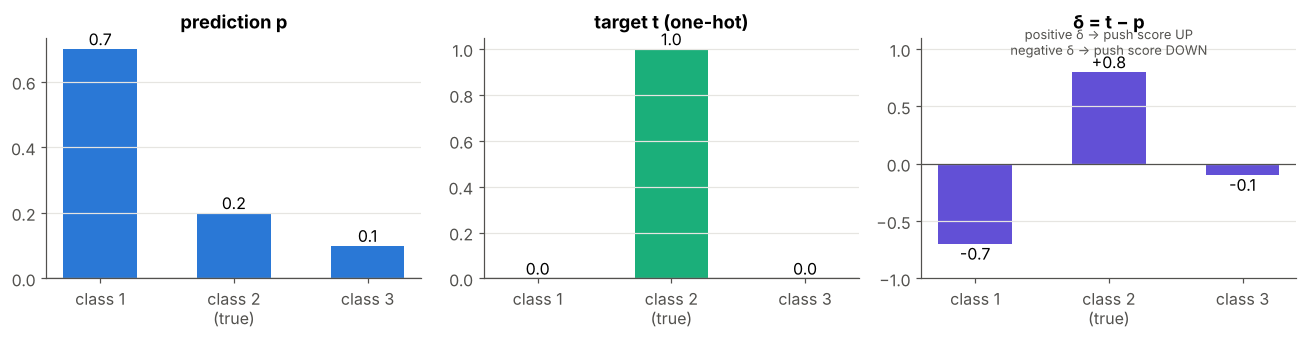

In [18]:
p_ex = np.array([0.7, 0.2, 0.1]); t_ex = np.array([0, 1, 0])
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
cls = ["class 1", "class 2\n(true)", "class 3"]
for ax, vals, title, col in [(axs[0], p_ex, "prediction p", C["blue"]), (axs[1], t_ex, "target t (one-hot)", C["aqua"]),
                             (axs[2], t_ex - p_ex, "δ = t − p", C["violet"])]:
    bars = ax.bar(cls, vals, color=col, width=0.55); ax.bar_label(bars, fmt="%+.1f" if "δ" in title else "%.1f")
    ax.axhline(0, color=C["muted"], lw=0.8); ax.set_title(title); ax.grid(axis="x", visible=False)
axs[2].set_ylim(-1, 1.1)
axs[2].text(1, 0.95, "positive δ → push score UP\nnegative δ → push score DOWN", ha="center", fontsize=8.5, color=C["muted"])
plt.tight_layout(); plt.show()

---
## 8 · Why cross-entropy trains faster than squared error ⚡

| task | output | loss | $\delta^{o}$ (notes' sign) |
|---|---|---|---|
| multi-class | softmax | cross-entropy | $T-P$ |
| binary | sigmoid | binary cross-entropy | $T-O$ |
| regression | identity | ½ squared error | $T-O$ |
| binary | sigmoid | ½ squared error (notes) | $(T-O)\odot O\odot(1-O)$ ← **slow when saturated** |

With squared error, the sigmoid slope $o(1-o)$ appears in $\delta$. With (binary) cross-entropy, it cancels. So when a neuron is **confidently wrong**, squared error gives almost no gradient, while cross-entropy gives the biggest one:

**Step A – the size of $\delta$ for both losses** as the net input $z$ varies (target 1):

In [19]:
zs = np.linspace(-8, 8, 400)
a = sigmoid(zs)
delta_ce = np.abs(1 - a)                       # cross-entropy:  |t - o|
delta_mse = np.abs((1 - a) * a * (1 - a))      # squared error:  |(t - o) o (1 - o)|
print(f"at z = -6:  CE |δ| = {delta_ce[np.searchsorted(zs, -6)]:.3f},  MSE |δ| = {delta_mse[np.searchsorted(zs, -6)]:.4f}")

at z = -6:  CE |δ| = 0.998,  MSE |δ| = 0.0025


**Step B – a race.** One sigmoid neuron with one input $x=1$ starts confidently wrong ($w=-4$, so $o\approx0.02$, target 1). Each step applies $\Delta w=\eta\ \delta\ x$ with either loss's $\delta$. We record the output after every step.

In [20]:
def train(loss, steps=60, eta=1.0):
    w, hist = -4.0, []
    for _ in range(steps):
        o_ = sigmoid(w * 1.0)
        hist.append(o_)
        d = (1 - o_) if loss == "ce" else (1 - o_) * o_ * (1 - o_)   # δ for each loss
        w += eta * d * 1.0                                         # Δw = η δ x
    return hist

race = {"ce": train("ce"), "mse": train("mse")}
print(f"after 60 steps: CE output = {race['ce'][-1]:.3f},  MSE output = {race['mse'][-1]:.3f}")

after 60 steps: CE output = 0.982,  MSE output = 0.179


📊 **Plot:** the learning-signal size (left) and the race (right).

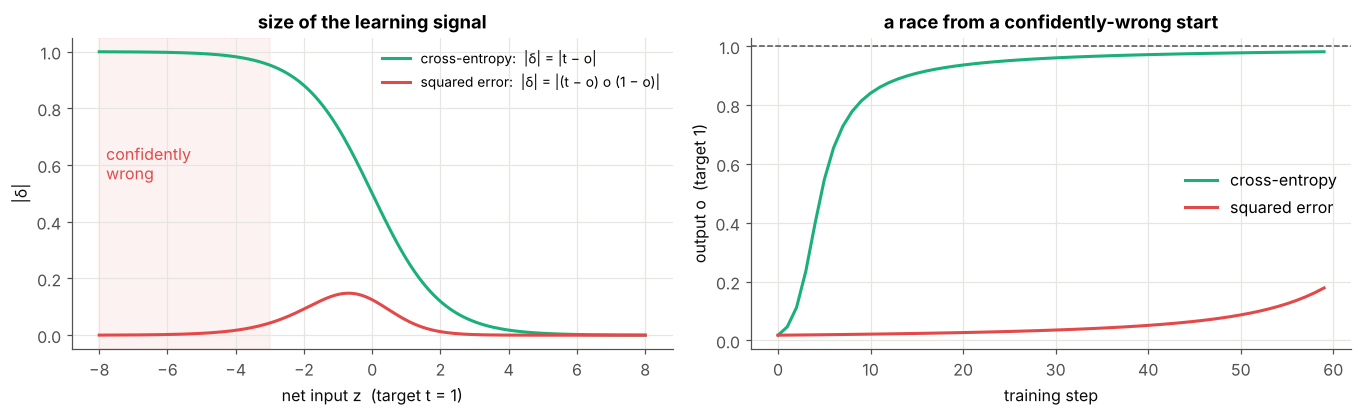

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9))
axs[0].plot(zs, delta_ce, color=C["aqua"], label="cross-entropy:  |δ| = |t − o|")
axs[0].plot(zs, delta_mse, color=C["red"], label="squared error:  |δ| = |(t − o) o (1 − o)|")
axs[0].axvspan(-8, -3, color=C["red"], alpha=0.07); axs[0].text(-7.8, 0.55, "confidently\nwrong", color=C["red"])
axs[0].set_xlabel("net input z  (target t = 1)"); axs[0].set_ylabel("|δ|"); axs[0].set_title("size of the learning signal")
axs[0].legend(loc="upper right", fontsize=9)

axs[1].plot(race["ce"], color=C["aqua"], label="cross-entropy")
axs[1].plot(race["mse"], color=C["red"], label="squared error")
axs[1].axhline(1, color=C["muted"], ls="--", lw=1)
axs[1].set_xlabel("training step"); axs[1].set_ylabel("output o  (target 1)"); axs[1].set_title("a race from a confidently-wrong start")
axs[1].legend()
plt.tight_layout(); plt.show()

---
## 9 · Summary 📌

| Item | Formula |
|---|---|
| error term (sigmoid + ½SE) | $\delta_k=(t_k-o_k)\ o_k(1-o_k)$ |
| error term (softmax + CE) | $\delta_k=t_k-p_k$ |
| single weight | $\Delta w_{kj}=\eta\ \delta_k\ x_{kj}$, $\ \Delta b_k=\eta\ \delta_k$ |
| matrix form | $\Delta W^{o}=\eta\ \delta^{o}(O^{h})^\top$, $\ \Delta b^{o}=\eta\sum_{\text{cols}}\delta^{o}$ |
| blame for the layer below | $\partial E/\partial O^{h}=-(W^{o})^\top\delta^{o}$ |
| gradient check | relative error $<10^{-6}$ ✅ |

### ✍️ Try it yourself
1. Add L2 regularisation $\frac\lambda2\lVert W\rVert^2$ to $E$. What is the new $\partial E/\partial W$? Verify with `numerical_grad`.
2. Break the gradient on purpose (drop the factor `O * (1 - O)`) and watch the relative error jump.
3. Derive $\delta$ for a sigmoid output with **binary** cross-entropy $E=-[t\log o+(1-t)\log(1-o)]$ and confirm it is $t-o$.
4. In the 2-2-1 example, how many updates does it take to bring $o$ above 0.9 with $\eta=0.5$?

**Next →** `04 - Backprop for Hidden Layers`: hidden neurons have no target – how do we blame them?